# 01 · Prepare the data

This notebook turns the two raw datasets into three ready-to-train files:

| File | Used for |
|---|---|
| `data/processed/train.npz` | training the model |
| `data/processed/val.npz` | picking the best model during training |
| `data/processed/test.npz` | final score (never seen during training) |

Every image becomes a **64×64 grayscale** eye crop with a label: **0 = closed, 1 = open**.

Run the cells top to bottom. Total time: about 1–2 minutes (longer the very first time Windows reads the files).

## 1. Settings
Paths, image size, and a fixed random seed so the split is the same every time you run this.

In [1]:
import os, re, random
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import cv2
import matplotlib.pyplot as plt

MRL_DIR = "data/mrl/mrleyedataset"
CEW_DIR = "data/cew/dataset_B_Eye_Images"
OUT_DIR = "data/processed"
IMG_SIZE = 64
SEED = 42
CLASSES = ["closed", "open"]

os.makedirs(OUT_DIR, exist_ok=True)

## 2. MRL dataset: list all images
File names hold the person ID, for example `s0001_00001_0_0_0_0_0_01.png` belongs to person `s0001`.
The folder name gives the label.

In [2]:
mrl = []  # (path, label, person)
for folder, label in [("Close-Eyes", 0), ("Open-Eyes", 1)]:
    for f in sorted(os.listdir(os.path.join(MRL_DIR, folder))):
        if f.endswith(".png"):
            mrl.append((os.path.join(MRL_DIR, folder, f), label, f.split("_")[0]))

print("MRL images:", len(mrl))
print("People:", len({person for _, _, person in mrl}))

MRL images: 84898
People: 37


## 3. MRL dataset: split by person
No person appears in more than one split, so the test score shows how the model does on **new people**.

The validation and test people were chosen so each split has ~15% of the images, a close to 50/50 mix
of open and closed eyes, people with and without glasses, and at least one woman.
Everyone else (23 people) goes to training.

In [3]:
VAL_PEOPLE  = {"s0001", "s0018", "s0027", "s0028", "s0029", "s0031", "s0034"}
TEST_PEOPLE = {"s0002", "s0005", "s0008", "s0011", "s0021", "s0035", "s0036"}

def mrl_split(person):
    if person in VAL_PEOPLE:
        return "val"
    if person in TEST_PEOPLE:
        return "test"
    return "train"

## 4. CEW dataset: list all images and split 70 / 15 / 15
CEW has normal camera photos (not infrared), which helps the model work on a webcam.
The left and right eye of the same photo always go to the same split.

In [4]:
cew = []  # (path, label, photo_id)
for folder, label in [("closedLeftEyes", 0), ("closedRightEyes", 0),
                      ("openLeftEyes", 1), ("openRightEyes", 1)]:
    for f in sorted(os.listdir(os.path.join(CEW_DIR, folder))):
        if f.endswith(".jpg"):
            photo = re.sub(r"(\.jpg_face_\d+)?_[LR]\.jpg$", "", f)  # strip eye side -> photo ID
            cew.append((os.path.join(CEW_DIR, folder, f), label, photo))

photos = sorted({photo for _, _, photo in cew})
random.Random(SEED).shuffle(photos)
n = len(photos)
cew_split = {}
for i, photo in enumerate(photos):
    cew_split[photo] = "train" if i < 0.70 * n else "val" if i < 0.85 * n else "test"

print("CEW images:", len(cew))
print("Photos:", n)

CEW images: 4846
Photos: 2370


## 5. Load, resize and save
Each image is read as grayscale and resized to 64×64, then saved per split.
`src` remembers which dataset an image came from, so we can score MRL and CEW separately later.

In [5]:
items = [(path, label, "mrl", mrl_split(person)) for path, label, person in mrl] + \
        [(path, label, "cew", cew_split[photo]) for path, label, photo in cew]

def load_image(path):
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    interp = cv2.INTER_AREA if img.shape[0] > IMG_SIZE else cv2.INTER_CUBIC
    return cv2.resize(img, (IMG_SIZE, IMG_SIZE), interpolation=interp)

for split in ["train", "val", "test"]:
    rows = [r for r in items if r[3] == split]
    with ThreadPoolExecutor() as pool:  # load images in parallel (faster)
        x = np.stack(list(pool.map(load_image, [r[0] for r in rows])))
    y = np.array([r[1] for r in rows], dtype=np.uint8)
    src = np.array([r[2] for r in rows])
    np.savez_compressed(os.path.join(OUT_DIR, f"{split}.npz"), x=x, y=y, src=src)
    print(f"{split:5s} saved: {len(y):6d} images")

train saved:  63227 images
val   saved:  13645 images
test  saved:  12872 images


## 6. Check the splits
How many images each split has, per dataset and per class.

In [6]:
print(f"{'split':6s} {'dataset':8s} {'closed':>7s} {'open':>7s} {'total':>7s}")
for split in ["train", "val", "test"]:
    d = np.load(os.path.join(OUT_DIR, f"{split}.npz"))
    for name in ["mrl", "cew"]:
        y = d["y"][d["src"] == name]
        print(f"{split:6s} {name:8s} {(y == 0).sum():7d} {(y == 1).sum():7d} {len(y):7d}")

split  dataset   closed    open   total
train  mrl        29473   30350   59823
train  cew         1718    1686    3404
val    mrl         6166    6757   12923
val    cew          358     364     722
test   mrl         6307    5845   12152
test   cew          308     412     720


## 7. Look at some training images
Top two rows: MRL (infrared). Bottom two rows: CEW (normal camera).

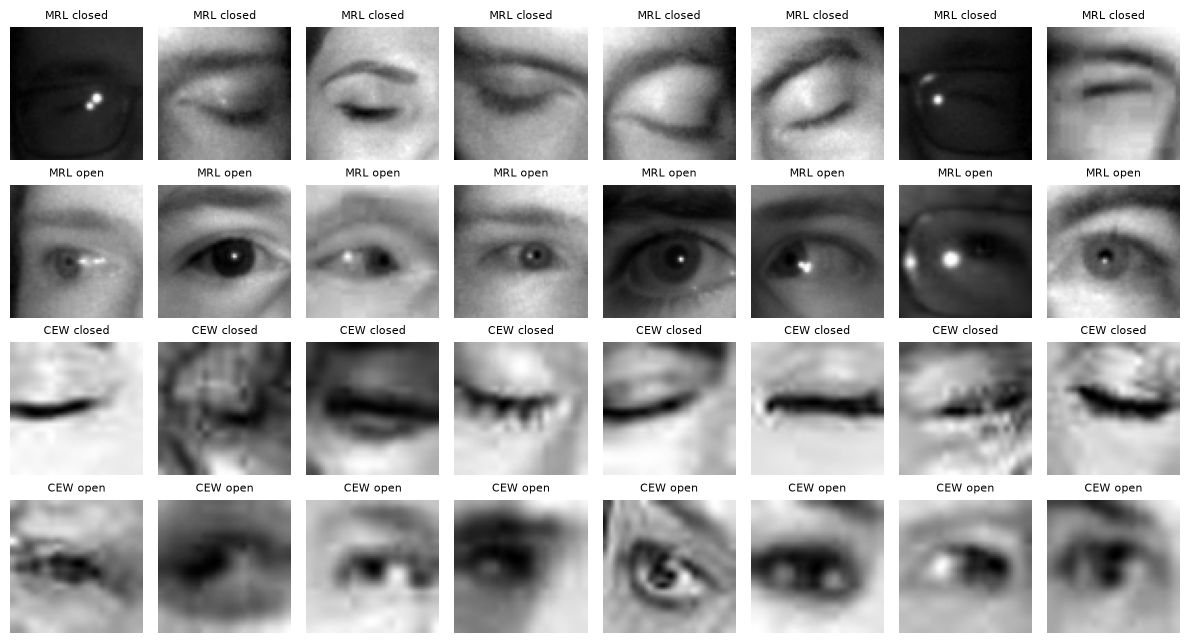

In [7]:
d = np.load(os.path.join(OUT_DIR, "train.npz"))
rng = np.random.default_rng(SEED)

fig, axes = plt.subplots(4, 8, figsize=(12, 6.5))
for row, (name, label) in enumerate([("mrl", 0), ("mrl", 1), ("cew", 0), ("cew", 1)]):
    idx = rng.choice(np.where((d["src"] == name) & (d["y"] == label))[0], 8, replace=False)
    for col, i in enumerate(idx):
        axes[row, col].imshow(d["x"][i], cmap="gray")
        axes[row, col].set_title(f"{name.upper()} {CLASSES[label]}", fontsize=8)
        axes[row, col].axis("off")
plt.tight_layout()
plt.show()